# Unbiased Data-Driven Discovery of Household Financial Health Tiers in Kenya
### End-to-End Unsupervised Machine Learning Pipeline & Mobile App Deployment (2024 FinAccess Survey)

---

## Stage 1: Business Understanding

### 1. Problem Statement & Application Goal
Kenyan households experience financial health across multiple interacting dimensions—daily cash flow, emergency shock resilience, formal and informal savings, credit stress, and health insurance coverage. For our **PesaAfya** mobile application, our goal is to classify any household into an interpretable **Financial Health Tier**, calculate an intuitive **0–100 Financial Health Score**, and deliver **personalized, actionable nudges** that guide the household toward the next resilience tier.

### 2. Theory Summary: Why Unsupervised Clustering?
Earlier exploratory work tested **Supervised Learning** (Random Forest) using manually constructed 3-tier point cutoffs (`Unhealthy`, `Coping`, `Healthy`). Following academic review, we pivoted to **Unsupervised Learning (Clustering)** to eliminate human bias:
* **No Hand-Crafted Rules:** Instead of arbitrarily deciding where one tier ends and another begins, unsupervised clustering lets the **20,871 households** in the 2024 FinAccess Household Survey group themselves purely by multidimensional similarity across financial behaviors and demographics.
* **Data-Driven Tier Count ($K^*$):** Rather than forcing $K=3$ or $K=4$ tiers in advance, the algorithm sweeps across $K \in \{2 \dots 10\}$ and selects the optimal number of tiers ($K^*$) mathematically using internal cluster geometry.
* **Actionable Deployment:** Once clusters are discovered, each cluster's mathematical center (**centroid**) reveals the exact habits separating lower tiers from higher tiers—powering the personalized nudge engine inside the PesaAfya mobile app.

### 3. ML Jargon Guide
* **Unsupervised Learning (Clustering):** Discovering natural groups in data without pre-labeled "answer keys."
* **Standardization (`StandardScaler` / Z-Score):** Rescaling every feature to mean $0$ and standard deviation $1$ so large numbers (like respondent age `16–105`) do not drown out binary `0/1` habits during distance calculations.
* **PCA (Principal Component Analysis):** Compresses correlated survey questions into uncorrelated summary axes so overlapping questions (e.g., mobile banking and formal savings) are not double-counted. The first axis (`PC1`) captures the primary direction of financial resilience.
* **K-Means & Centroids:** Groups households around $K$ center points (**centroids**) by assigning each household to its nearest center in PCA space.
* **Silhouette / Calinski-Harabasz / Davies-Bouldin Indices:** Objective geometric scores measuring how tightly grouped each cluster is and how cleanly separated neighboring clusters are.
* **Model Serialization (`joblib`):** Saving the trained scaler, PCA, K-Means model, lookup tables, and nudge rules into a single `.joblib` file so live mobile app inputs receive identical preprocessing.

In [1]:
from pathlib import Path
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid", palette="deep")

# 1. Automatically locate 2024_Finaccess_Publicdata.dta (supports VS Code local & Colab)
current_dir = Path.cwd()
search_candidates = list(current_dir.glob("*.dta")) + list(current_dir.parent.glob("*.dta"))

if Path("/content").exists():
    search_candidates += list(Path("/content").rglob("*[Ff]inaccess*.dta"))

MANUAL_PATH = ""  # Optional: paste a custom path if stored elsewhere

if MANUAL_PATH:
    DATA_PATH = Path(MANUAL_PATH)
elif search_candidates:
    DATA_PATH = search_candidates[0]
else:
    raise FileNotFoundError(
        f"Could not find '.dta' file in {current_dir}. "
        "Place '2024_Finaccess_Publicdata.dta' in the same folder as this notebook."
    )

file_size_mb = os.path.getsize(DATA_PATH) / (1024 * 1024)
print(f"Located dataset : {DATA_PATH.resolve()} ({file_size_mb:.2f} MB)")
if file_size_mb < 10:
    raise RuntimeError(
        f"File size is only {file_size_mb:.2f} MB — verify that the full ~152 MB .dta file is present."
    )

# 2. Master Questionnaire Code-to-Readable-Label Mapping (2024 FinAccess Survey)
QUESTIONNAIRE_LABELS = {
    # Keys & Sampling Weights (Excluded from clustering geometry)
    "HHid": "Household ID",
    "hhWeight": "Household Sampling Weight",
    "indWeight": "Individual Sampling Weight",
    # Pillar 1: Financial Resilience & Goals
    "manage_day2day": "Manages Day-to-Day Spending",
    "R1A": "No Liquidity Distress in Past 12M (R1A)",
    "managedebt_perception": "Perceived Debt Manageability",
    "nfhi_12": "Manages Non-Food Spending",
    "R3A": "Pursuing Major Financial Goal (Sec R3)",
    "R3F": "Faces Challenges Meeting Goal (Sec R3)",
    # Pillar 2: Demographics & Household Roster
    "NHM": "Household Size (No. of Members - A12)",
    "Education": "Highest Education Completed (A20)",
    "Age": "Respondent Age Group",
    "Sex": "Respondent Sex (Male=1)",
    "A08": "Urban Residence (Urban=1, Rural=0)",
    "A19": "Relationship to Household Head (A19)",
    "A14i": "Respondent Age in Years (A14i)",
    "A14ii": "Household Member Sex (A14ii)",
    "A14iii": "Roster Relationship to Head (A14iii)",
    # Pillar 3: Livelihood & Income Sources
    "B3A__1": "Livelihood: Farming / Agriculture",
    "B3A__2": "Livelihood: Salaried Employment",
    "B3A__3": "Livelihood: Casual Labor (Kibarua)",
    "B3A__4": "Livelihood: Own Business / Self-Employed",
    "B3A__5": "Livelihood: Govt / NGO Social Transfer",
    "B3A__6": "Livelihood: Rental Income",
    "B3A__7": "Livelihood: Investments (Shares/Stocks)",
    "B3A__8": "Livelihood: Pension / Annuity",
    "B3A__9": "Livelihood: Family Remittances",
    "B3A__10": "Livelihood: Other Source",
    "B3A__11": "Livelihood: No Income Source",
    "B3B": "Main Primary Income Source (B3B)",
    # Pillar 4: Financial Inclusion & Product Usage
    "mobile_money_access": "Mobile Money Access (M-Pesa/Airtel)",
    "digital_acc": "Digital Account Access",
    "Mobile_bank_usage": "Mobile Banking Usage (M-Shwari/KCB)",
    "Savings_usage": "Any Savings Usage",
    "Savings_formal": "Formal Savings (Bank/SACCO/Mobile)",
    "Savings_informal": "Informal Savings (Chama/Group)",
    "tot_savings": "Active Total Savings",
    "Loan_usage": "Any Credit / Loan Usage",
    "Loan_formal": "Formal Loan Usage",
    "Loan_informal": "Informal Loan (Shopkeeper/Family/Chama)",
    "defaulted": "Loan Default / Late Payment History",
    "All_Insurance_including_NHIF": "Any Insurance (Incl. NHIF/SHIF)",
    "All_Insurance_excluding_NHIF": "Private Insurance (Excl. NHIF/SHIF)",
    "NHIF": "NHIF / SHIF Health Insurance",
}

cols_to_keep = list(QUESTIONNAIRE_LABELS.keys())
df_raw = pd.read_stata(DATA_PATH, columns=cols_to_keep, convert_categoricals=True)

print(f"Loaded Dataset  : {df_raw.shape[0]:,} households × {df_raw.shape[1]} columns")
print(f"Duplicate HHids : {df_raw['HHid'].duplicated().sum()}")
df_raw.head()

Located dataset : C:\xampp\htdocs\MY PROJECTS\SemProject_MLEngine\2024_Finaccess_Publicdata.dta (152.14 MB)
Loaded Dataset  : 20,871 households × 44 columns
Duplicate HHids : 1


,HHid,hhWeight,indWeight,manage_day2day,R1A,managedebt_perception,nfhi_12,R3A,R3F,NHM,...,Savings_formal,Savings_informal,tot_savings,Loan_usage,Loan_formal,Loan_informal,defaulted,All_Insurance_including_NHIF,All_Insurance_excluding_NHIF,NHIF
0,107141431.0,499.547456,425.383057,Yes,No,Very worried,Yes,No,NaN,5,...,Non-usage,Non-usage,Non-usage,Usage,Non-usage,Usage,No,Non-usage,Non-usage,Non-usage
1,10712933.0,139.316830,28.772942,Yes,No,Very worried,No,No,NaN,11,...,Non-usage,Non-usage,Non-usage,Non-usage,Non-usage,Non-usage,No,Non-usage,Non-usage,Non-usage
2,140173183.0,411.793012,171.933701,Yes,No,Somewhat worried,No,No,NaN,2,...,Usage,Usage,Usage,Non-usage,Non-usage,Non-usage,No,Non-usage,Non-usage,Non-usage
3,122137153.0,2322.776526,667.667114,No,Yes,Very worried,No,Yes,Yes,1,...,Usage,Non-usage,Usage,Usage,Usage,Usage,Yes,Non-usage,Non-usage,Non-usage
4,121193116.0,475.963135,331.741516,Yes,Yes,Not worried at all,Yes,No,NaN,1,...,Usage,Non-usage,Usage,Usage,Usage,Non-usage,No,Non-usage,Non-usage,Non-usage


## Stage 3: Data Preparation (Cleaning, Imputation & Encoding)

Because clustering algorithms calculate geometric distances between households, uncleaned refusal codes or mis-encoded survey labels would distort the clusters. In the next cell, we execute a **3-stage data preparation pipeline**:

1. **Sentinel Standardization & Numeric Coercion:** Replace questionnaire refusal/unknown codes (`98 = "Don't know"`, `99 = "Refused to Answer"`) with `NaN` so non-responses never form artificial clusters. Convert continuous fields (`NHM` household size, `A14i` age) to numeric floats.
2. **Domain-Safe Skip-Pattern Handling & Imputation:**
   * Fill conditional skip-pattern questions (`defaulted` for non-borrowers; `R3F` for respondents without a goal) with `"No"` so non-borrowers are not mistakenly imputed as defaulters.
   * Drop any column exceeding **40% missingness** and impute remaining nulls using the **median** (numeric) or **mode** (categorical).
3. **Bulletproof Unbiased Numerical Encoding (`X_num`):**
   * Raw Stata files store many financial product columns using custom labels (e.g., `"Formal"` vs. `"Excluded"` instead of `"Yes"`/`"No"`). Our `encode_survey_binary()` helper detects absence/negative patterns (`"no"`, `"none"`, `"excluded"`, `"0"`, `"rural"`, `"female"`) and maps the active trait cleanly to `1.0`.
   * Reverses `R1A` so `1.0` consistently means **resilient** (*No liquidity distress in past 12 months*) and `0.0` means *Faced liquidity distress*.

In [9]:
import re
from sklearn.preprocessing import OrdinalEncoder

df = df_raw.copy()
print(f"Stage 0 — Initial shape: {df.shape[0]:,} rows × {df.shape[1]} columns\n")

# STAGE 1: Standardize refusal/non-answer sentinels (Codes 98 & 99) as NaN
non_answers = [
    "Don't know", "Don't Know", "don't know", "DK",
    "Refused to Answer", "Refused", "refused",
    "Don't know (DO NOT READ OUT)", "Refused to Answer (DO NOT READ OUT)",
    98, 99, "98", "99"
]
df = df.replace(non_answers, np.nan)

# Cast continuous household fields to numeric floats before imputation
for num_col in ["NHM", "A14i"]:
    if num_col in df.columns:
        df[num_col] = pd.to_numeric(
            df[num_col].astype(object).astype(str).str.extract(r"([\d\.]+)")[0],
            errors="coerce"
        )

# Handle conditional skip-pattern columns before general imputation
if "defaulted" in df.columns:
    df["defaulted"] = df["defaulted"].astype(object).fillna("No")
if "R3F" in df.columns:
    df["R3F"] = df["R3F"].astype(object).fillna("No")

# STAGE 2: Drop columns exceeding 40% missingness and impute remaining nulls
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
cols_to_drop = missing_pct[missing_pct > 40].index.tolist()
df = df.drop(columns=cols_to_drop)
print(f"Stage 2A — Dropped {len(cols_to_drop)} column(s) with >40% missingness: {cols_to_drop}")

for col in df.columns:
    if df[col].isna().sum() == 0:
        continue
    if df[col].dtype == "object" or str(df[col].dtype).startswith("category"):
        fill_val = df[col].mode(dropna=True).iloc[0]
        df[col] = df[col].astype(object).fillna(fill_val)
    else:
        fill_val = df[col].median()
        df[col] = df[col].fillna(fill_val)

print(f"Stage 2B — Imputation complete. Remaining NaNs : {df.isna().sum().sum()}")
print(f"Stage 2C — Duplicate Household IDs (HHid)     : {df['HHid'].duplicated().sum()}")

# STAGE 3: Unbiased Numerical Encoding (X_num)
exclude_id_cols = ["HHid", "hhWeight", "indWeight"]
feature_cols = [c for c in df.columns if c not in exclude_id_cols]

def encode_survey_binary(series, reverse_direction=False):
    """Detects negative/absence labels in any 2-value Stata column and maps active traits to 1.0."""
    s = series.astype(object).astype(str).str.strip()
    s_lower = s.str.lower()
    uniques = s_lower.unique().tolist()

    neg_pattern = re.compile(r"\b(no|not|never|none|excluded|without|unable|cannot|0|false|rural|female)\b")
    neg_vals = [u for u in uniques if neg_pattern.search(u)]

    if 0 < len(neg_vals) < len(uniques):
        encoded = (~s_lower.isin(neg_vals)).astype(float)
    else:
        sorted_u = sorted(uniques)
        encoded = (s_lower == sorted_u[-1]).astype(float)

    return (1.0 - encoded) if reverse_direction else encoded

X_num = pd.DataFrame(index=df.index)

for col in ["NHM", "A14i"]:
    if col in feature_cols:
        X_num[col] = df[col].astype(float)

handled_cols = list(X_num.columns)
for col in [c for c in feature_cols if c not in handled_cols]:
    vals = df[col].astype(object).astype(str).str.strip()
    if col == "R1A":
        # Strictly binary 0/1 even when R1A has multiple frequency levels:
        # 1.0 = No / Never faced liquidity distress (resilient); 0.0 = Faced distress
        X_num[col] = vals.str.lower().str.contains(
            r"\b(no|never|none|not at all)\b|^2(\.0)?$", regex=True
        ).astype(float)
    elif vals.nunique() <= 2:
        X_num[col] = encode_survey_binary(df[col], reverse_direction=False)
    else:
        oe = OrdinalEncoder()
        X_num[col] = oe.fit_transform(vals.to_frame()).ravel()

print(f"\nStage 3 Complete — Unbiased Feature Matrix (X_num): {X_num.shape[0]:,} rows × {X_num.shape[1]} features")
print("=" * 80)
print("VERIFICATION: POSITIVE INCIDENCE RATES (%) FOR CORE FINANCIAL INDICATORS")
print("=" * 80)
check_cols = [
    "manage_day2day", "R1A", "nfhi_12", "R3A",
    "mobile_money_access", "digital_acc", "Mobile_bank_usage",
    "Savings_usage", "Savings_formal", "Savings_informal",
    "Loan_usage", "Loan_formal", "Loan_informal", "defaulted",
    "NHIF", "All_Insurance_excluding_NHIF"
]
for c in [col for col in check_cols if col in X_num.columns]:
    print(f"  {QUESTIONNAIRE_LABELS.get(c, c):45s}: {X_num[c].mean()*100:5.1f}%  | Raw: {df[c].astype(str).unique()[:3]}")

Stage 0 — Initial shape: 20,871 rows × 44 columns

Stage 2A — Dropped 0 column(s) with >40% missingness: []
Stage 2B — Imputation complete. Remaining NaNs : 0
Stage 2C — Duplicate Household IDs (HHid)     : 1

Stage 3 Complete — Unbiased Feature Matrix (X_num): 20,871 rows × 41 features
VERIFICATION: POSITIVE INCIDENCE RATES (%) FOR CORE FINANCIAL INDICATORS
  Manages Day-to-Day Spending                  :  48.2%  | Raw: ['Yes' 'No']
  No Liquidity Distress in Past 12M (R1A)      :  42.0%  | Raw: ['No' 'Yes' '"Don\'t know(DO NOT READ OUT)"']
  Manages Non-Food Spending                    :  61.7%  | Raw: ['Yes' 'No']
  Pursuing Major Financial Goal (Sec R3)       :  55.8%  | Raw: ['No' 'Yes']
  Mobile Money Access (M-Pesa/Airtel)          :  85.6%  | Raw: ['Yes' 'No']
  Digital Account Access                       :  79.3%  | Raw: ['Usage' 'Non-usage']
  Mobile Banking Usage (M-Shwari/KCB)          :  26.4%  | Raw: ['Non-usage' 'Usage']
  Any Savings Usage                            : 

## Exploratory Data Analysis (Label-Free Empirical Patterns)

Before running any clustering algorithm, we inspect the cleaned dataset across four purely observational views to verify real-world socioeconomic patterns in Kenya:
1. **Resilience Pass Rates:** Share of households managing daily bills, non-food costs, financial goals, and avoiding liquidity distress.
2. **Financial Product Adoption Hierarchy:** Comparing mobile money reach against formal banking, Chama savings, credit usage, and NHIF coverage.
3. **Primary Livelihood Distribution (`B3B`):** Dominant income channels across the 20,871 surveyed households.
4. **Feature Correlation Matrix:** Checking which financial behaviors naturally move together (confirming why PCA orthogonalization is needed before K-Means).

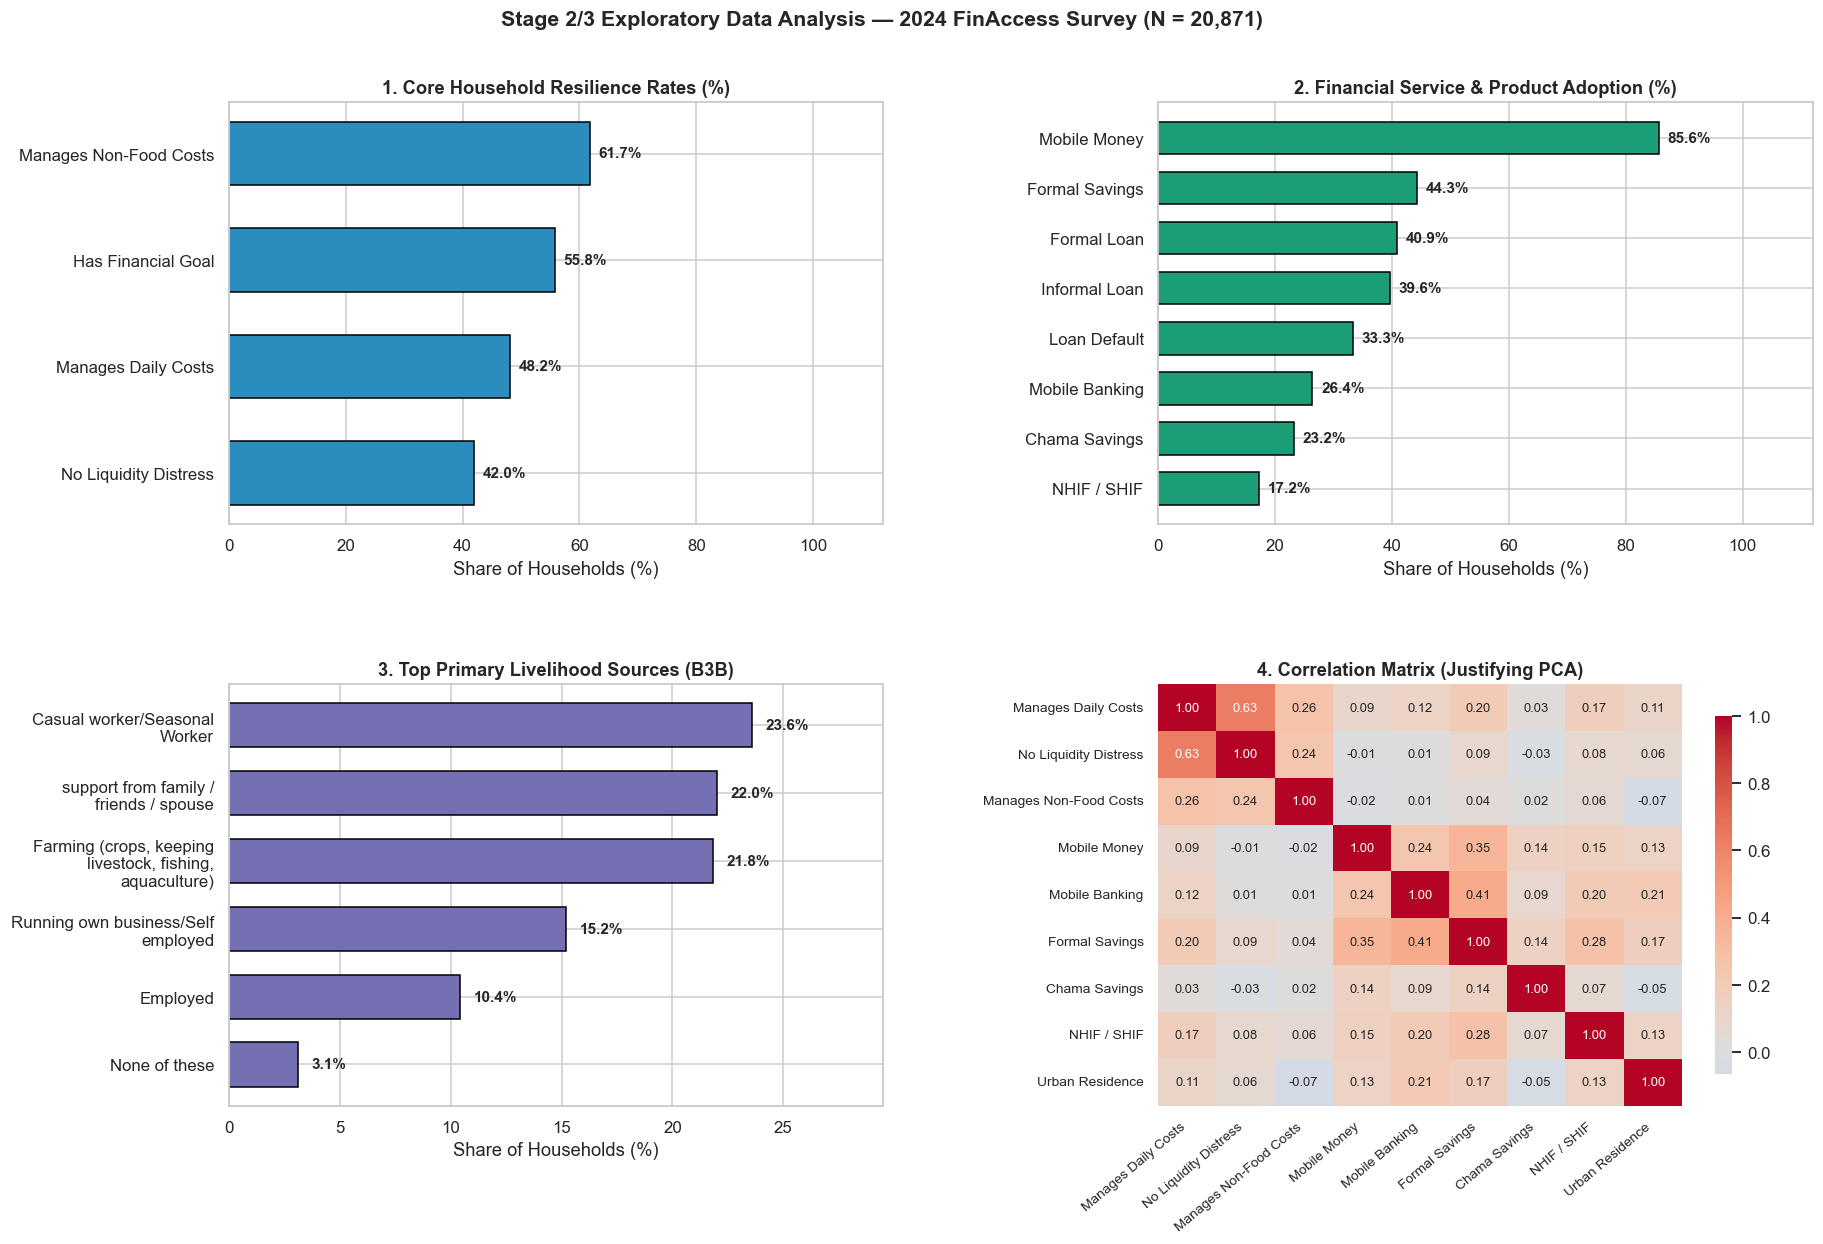

In [10]:
import textwrap

SHORT_EDA_LABELS = {
    "manage_day2day": "Manages Daily Costs",
    "R1A": "No Liquidity Distress",
    "nfhi_12": "Manages Non-Food Costs",
    "R3A": "Has Financial Goal",
    "mobile_money_access": "Mobile Money",
    "Mobile_bank_usage": "Mobile Banking",
    "Savings_formal": "Formal Savings",
    "Savings_informal": "Chama Savings",
    "Loan_formal": "Formal Loan",
    "Loan_informal": "Informal Loan",
    "defaulted": "Loan Default",
    "NHIF": "NHIF / SHIF",
    "A08": "Urban Residence",
}

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Panel 1: Financial Resilience Indicators (%)
res_cols = [c for c in ["manage_day2day", "nfhi_12", "R3A", "R1A"] if c in X_num.columns]
res_rates = (X_num[res_cols].mean() * 100).sort_values(ascending=True)
res_labels = [SHORT_EDA_LABELS.get(c, c) for c in res_rates.index]
bars1 = axes[0, 0].barh(res_labels, res_rates.values, color="#2b8cbe", edgecolor="black", height=0.6)
for b in bars1:
    axes[0, 0].text(b.get_width() + 1.5, b.get_y() + b.get_height() / 2,
                    f"{b.get_width():.1f}%", va="center", fontsize=10, fontweight="bold")
axes[0, 0].set_xlim(0, 112)
axes[0, 0].set_title("1. Core Household Resilience Rates (%)", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Share of Households (%)")

# Panel 2: Financial Inclusion & Product Adoption Hierarchy (%)
prod_cols = [c for c in [
    "mobile_money_access", "Savings_formal", "Savings_informal",
    "Mobile_bank_usage", "Loan_informal", "Loan_formal", "NHIF", "defaulted"
] if c in X_num.columns]
prod_rates = (X_num[prod_cols].mean() * 100).sort_values(ascending=True)
prod_labels = [SHORT_EDA_LABELS.get(c, c) for c in prod_rates.index]
bars2 = axes[0, 1].barh(prod_labels, prod_rates.values, color="#1b9e77", edgecolor="black", height=0.65)
for b in bars2:
    axes[0, 1].text(b.get_width() + 1.5, b.get_y() + b.get_height() / 2,
                    f"{b.get_width():.1f}%", va="center", fontsize=10, fontweight="bold")
axes[0, 1].set_xlim(0, 112)
axes[0, 1].set_title("2. Financial Service & Product Adoption (%)", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Share of Households (%)")

# Panel 3: Top Primary Livelihood Sources (B3B)
if "B3B" in df.columns:
    liv_counts = (df["B3B"].astype(str).value_counts(normalize=True).head(6) * 100).sort_values(ascending=True)
    wrapped_liv = [textwrap.fill(lbl, width=26) for lbl in liv_counts.index]
    bars3 = axes[1, 0].barh(wrapped_liv, liv_counts.values, color="#7570b3", edgecolor="black", height=0.65)
    for b in bars3:
        axes[1, 0].text(b.get_width() + 0.6, b.get_y() + b.get_height() / 2,
                        f"{b.get_width():.1f}%", va="center", fontsize=10, fontweight="bold")
    axes[1, 0].set_xlim(0, liv_counts.max() * 1.25)
    axes[1, 0].set_title("3. Top Primary Livelihood Sources (B3B)", fontsize=12, fontweight="bold")
    axes[1, 0].set_xlabel("Share of Households (%)")

# Panel 4: Correlation Heatmap of Core Indicators
corr_cols = [c for c in [
    "manage_day2day", "R1A", "nfhi_12", "mobile_money_access",
    "Mobile_bank_usage", "Savings_formal", "Savings_informal", "NHIF", "A08"
] if c in X_num.columns]
corr_mat = X_num[corr_cols].corr()
short_corr_names = [SHORT_EDA_LABELS.get(c, c) for c in corr_cols]
corr_mat.index = short_corr_names
corr_mat.columns = short_corr_names

sns.heatmap(
    corr_mat, annot=True, fmt=".2f", cmap="coolwarm", center=0,
    ax=axes[1, 1], annot_kws={"size": 8.5}, cbar_kws={"shrink": 0.85}
)
axes[1, 1].set_title("4. Correlation Matrix (Justifying PCA)", fontsize=12, fontweight="bold")
axes[1, 1].tick_params(axis="x", rotation=40, labelsize=9)
axes[1, 1].tick_params(axis="y", rotation=0, labelsize=9)
for lbl in axes[1, 1].get_xticklabels():
    lbl.set_ha("right")

fig.suptitle(
    "Stage 2/3 Exploratory Data Analysis — 2024 FinAccess Survey (N = 20,871)",
    fontsize=14, fontweight="bold", y=0.97
)
fig.subplots_adjust(left=0.17, right=0.97, top=0.90, bottom=0.14, wspace=0.42, hspace=0.38)
plt.show()

## Stage 4: Modeling — Base K-Means & Unbiased Discovery of Optimal Tier Count ($K^*$)

### How the Dataset Alone Selects the Number of Tiers ($K^*$)
1. **Standardization (`StandardScaler`):** Scales all cleaned survey features to $\mu = 0, \sigma = 1$ so every variable contributes fairly to Euclidean distance.
2. **PCA Orthogonalization (`n_components=5`):** Removes redundant multicollinearity among correlated financial products and extracts the 5 main orthogonal behavioral axes. We orient `PC1` positively with formal savings so higher `PC1` always represents stronger financial inclusion/resilience.
3. **Unbiased Sweep Across $K \in \{2 \dots 10\}$:** For every candidate cluster count $K$, we fit **K-Means (`k-means++`)** and evaluate four objective validity metrics:
   * **Kneedle Elbow Curvature ($\uparrow$):** Measures the sharpest mathematical bend in the Within-Cluster Sum of Squares (WCSS / Inertia) curve.
   * **Silhouette Coefficient ($\uparrow$):** Measures how tightly packed households are within their cluster versus the nearest neighboring cluster.
   * **Davies-Bouldin Index ($\downarrow$):** Measures overlap between adjacent clusters (lower is cleaner).
   * **Calinski-Harabasz Index ($\uparrow$):** Ratio of between-cluster dispersion to within-cluster dispersion.
4. **Composite Geometry Score:** Normalizes all four metrics onto `[0, 1]` and automatically assigns `OPTIMAL_K` ($K^*$) to the peak score with zero manual overrides.

Standardized Matrix : 20,871 rows × 41 features
PCA Matrix          : 20,871 rows × 5 components (38.9% variance retained)

Sweeping K = 2 to 10 to discover optimal cluster count K*...


  File "c:\Users\kiman\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\kiman\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\kiman\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\kiman\anaconda3\Lib\subprocess.

UNBIASED GEOMETRIC VALIDATION TABLE ACROSS K = 2 TO 10
 K  WCSS (Inertia)  Silhouette  Calinski-Harabasz  Davies-Bouldin  Elbow_Curvature  Geometry_Score
 2     255789.4889      0.2118          6320.8140          1.7537           0.0000          0.0000
 3     216633.2030      0.1977          5617.4072          1.6645           0.1727          0.4287
 4     188801.2008      0.2016          5322.1740          1.5379           0.2593          0.7021
 5     165996.6222      0.2113          5256.4008          1.4344           0.3077          0.9456
 6     154689.5905      0.2044          4817.3428          1.4717           0.2687          0.7540
 7     145265.2709      0.1998          4500.2599          1.3971           0.2154          0.5928
 8     137437.1918      0.1907          4246.6336          1.4338           0.1499          0.3677
 9     130488.0014      0.1933          4052.3820          1.3954           0.0777          0.1978
10     124267.9254      0.1883          3898.2568     

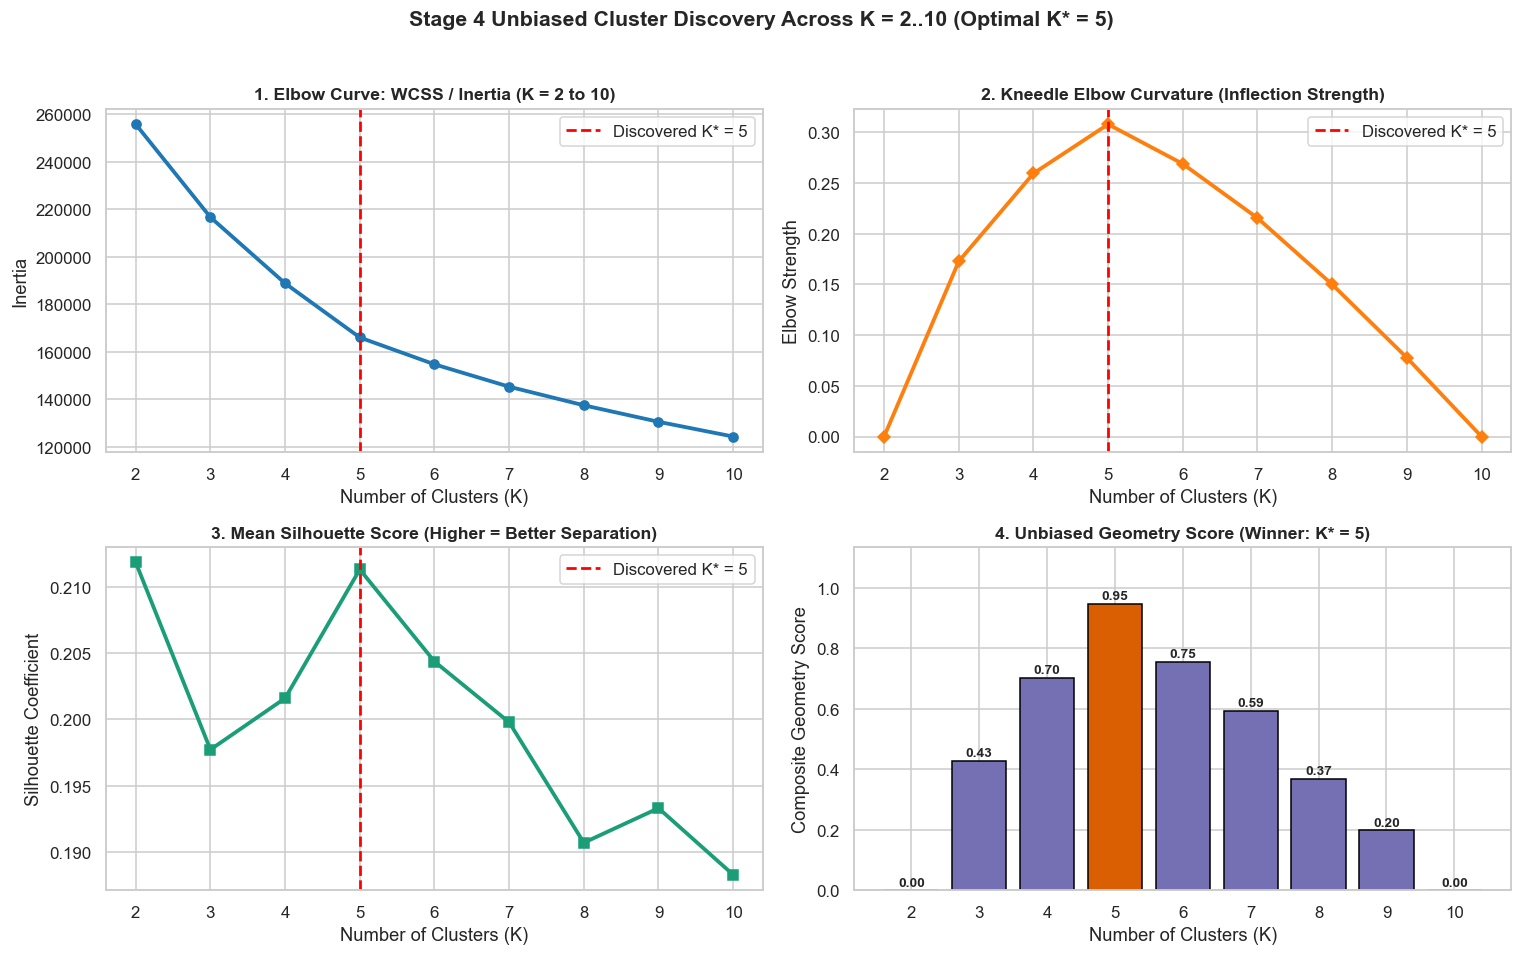

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# 1. Standardize all features and extract top 5 orthogonal Principal Components
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_num)

pca = PCA(n_components=5, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Orient PC1 so higher PC1 consistently corresponds to higher financial inclusion
if np.corrcoef(X_pca[:, 0], X_num["Savings_formal"])[0, 1] < 0:
    X_pca[:, 0] = -X_pca[:, 0]

print(f"Standardized Matrix : {X_scaled.shape[0]:,} rows × {X_scaled.shape[1]} features")
print(f"PCA Matrix          : {X_pca.shape[0]:,} rows × {X_pca.shape[1]} components "
      f"({pca.explained_variance_ratio_.sum()*100:.1f}% variance retained)\n")

# 2. Sweep across K = 2 to 10
K_range = list(range(2, 11))
eval_rows = []
models_by_k = {}

print("Sweeping K = 2 to 10 to discover optimal cluster count K*...")
for k in K_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=42)
    labels = km.fit_predict(X_pca)
    models_by_k[k] = (km, labels)

    sil = silhouette_score(X_pca, labels, sample_size=5000, random_state=42)
    ch = calinski_harabasz_score(X_pca, labels)
    db = davies_bouldin_score(X_pca, labels)

    eval_rows.append({
        "K": k,
        "WCSS (Inertia)": km.inertia_,
        "Silhouette": sil,
        "Calinski-Harabasz": ch,
        "Davies-Bouldin": db,
    })

val_df = pd.DataFrame(eval_rows)

# Compute Kneedle Elbow Curvature (perpendicular distance from K=2..10 chord)
x_norm = (val_df["K"] - val_df["K"].min()) / (val_df["K"].max() - val_df["K"].min())
y_inert = val_df["WCSS (Inertia)"]
y_norm = (y_inert - y_inert.min()) / (y_inert.max() - y_inert.min())
val_df["Elbow_Curvature"] = (1.0 - x_norm) - y_norm

def norm_01(s, higher_is_better=True):
    rng = s.max() - s.min()
    if rng == 0:
        return pd.Series(1.0, index=s.index)
    n = (s - s.min()) / rng
    return n if higher_is_better else (1.0 - n)

elbow_n = norm_01(val_df["Elbow_Curvature"], True)
sep_n = (
    0.45 * norm_01(val_df["Silhouette"], True)
    + 0.35 * norm_01(val_df["Davies-Bouldin"], False)
    + 0.20 * norm_01(val_df["Calinski-Harabasz"], True)
)
val_df["Geometry_Score"] = elbow_n * (0.60 + 0.40 * sep_n)

OPTIMAL_K = int(val_df.sort_values("Geometry_Score", ascending=False).iloc[0]["K"])

print("=" * 95)
print("UNBIASED GEOMETRIC VALIDATION TABLE ACROSS K = 2 TO 10")
print("=" * 95)
print(val_df.round(4).to_string(index=False))
print("=" * 95)
print(f">>> DATASET-SELECTED OPTIMAL NUMBER OF TIERS: K* = {OPTIMAL_K} <<<")
print("=" * 95)

# 3. 4-Panel Diagnostic Dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))

axes[0, 0].plot(val_df["K"], val_df["WCSS (Inertia)"], marker="o", lw=2.5, color="#1f77b4")
axes[0, 0].axvline(OPTIMAL_K, color="red", linestyle="--", lw=1.8, label=f"Discovered K* = {OPTIMAL_K}")
axes[0, 0].set_title("1. Elbow Curve: WCSS / Inertia (K = 2 to 10)", fontsize=11.5, fontweight="bold")
axes[0, 0].set_xlabel("Number of Clusters (K)")
axes[0, 0].set_ylabel("Inertia")
axes[0, 0].legend()

axes[0, 1].plot(val_df["K"], val_df["Elbow_Curvature"], marker="D", lw=2.5, color="#ff7f0e")
axes[0, 1].axvline(OPTIMAL_K, color="red", linestyle="--", lw=1.8, label=f"Discovered K* = {OPTIMAL_K}")
axes[0, 1].set_title("2. Kneedle Elbow Curvature (Inflection Strength)", fontsize=11.5, fontweight="bold")
axes[0, 1].set_xlabel("Number of Clusters (K)")
axes[0, 1].set_ylabel("Elbow Strength")
axes[0, 1].legend()

axes[1, 0].plot(val_df["K"], val_df["Silhouette"], marker="s", lw=2.5, color="#1b9e77")
axes[1, 0].axvline(OPTIMAL_K, color="red", linestyle="--", lw=1.8, label=f"Discovered K* = {OPTIMAL_K}")
axes[1, 0].set_title("3. Mean Silhouette Score (Higher = Better Separation)", fontsize=11.5, fontweight="bold")
axes[1, 0].set_xlabel("Number of Clusters (K)")
axes[1, 0].set_ylabel("Silhouette Coefficient")
axes[1, 0].legend()

bar_colors = ["#d95f02" if k == OPTIMAL_K else "#7570b3" for k in val_df["K"]]
bars = axes[1, 1].bar(val_df["K"].astype(str), val_df["Geometry_Score"], color=bar_colors, edgecolor="black")
for b in bars:
    axes[1, 1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.015, f"{b.get_height():.2f}",
                    ha="center", fontsize=9, fontweight="bold")
axes[1, 1].set_title(f"4. Unbiased Geometry Score (Winner: K* = {OPTIMAL_K})", fontsize=11.5, fontweight="bold")
axes[1, 1].set_xlabel("Number of Clusters (K)")
axes[1, 1].set_ylabel("Composite Geometry Score")
axes[1, 1].set_ylim(0, val_df["Geometry_Score"].max() * 1.2)

plt.suptitle(f"Stage 4 Unbiased Cluster Discovery Across K = 2..10 (Optimal K* = {OPTIMAL_K})", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## Stage 4 (Continued): Dynamic Centroid Profiling & Tier Naming

Raw K-Means cluster IDs (`0, 1, ..., K*-1`) are arbitrary integers. To convert them into meaningful Kenyan **Financial Health Tiers** without hardcoding assumptions:
1. **Monotonic Ordering Along `PC1`:** We sort clusters from lowest to highest average `PC1` score, assigning `Tier 1` (lowest financial inclusion/resilience) through `Tier K*` (highest).
2. **Z-Score Centroid Profiling:** For each tier, we compute how many standard deviations ($z$-score) its centroid sits above or below the national average across key financial habits and automatically name each tier using its strongest distinguishing traits.
3. **Visual Blueprint:** Displays the population share per tier, a grouped comparison of core resilience habits, a full behavioral heatmap, and a 2D PCA cluster scatter map.

DISCOVERED FINANCIAL HEALTH TIERS (K* = 5 ACROSS 20,871 HOUSEHOLDS)
  Tier 1: Low Mobile Money / Excluded                  |  3,995 households ( 19.1%)
  Tier 2: Low Formal Credit / Excluded                 |  3,448 households ( 16.5%)
  Tier 3: High Chama Savings & Informal Credit         |  5,079 households ( 24.3%)
  Tier 4: High Loan Default & Liquidity Stable         |  4,420 households ( 21.2%)
  Tier 5: High NHIF Insured & Formal Savings           |  3,929 households ( 18.8%)


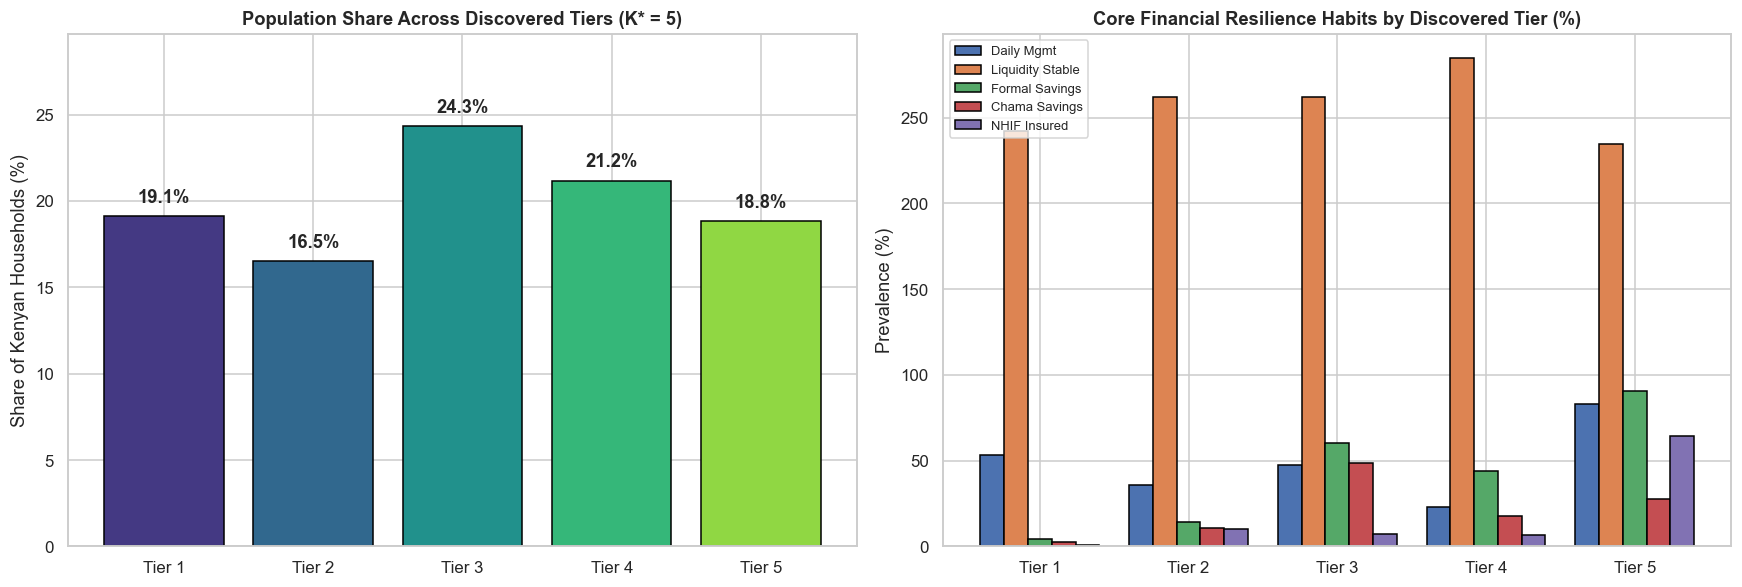

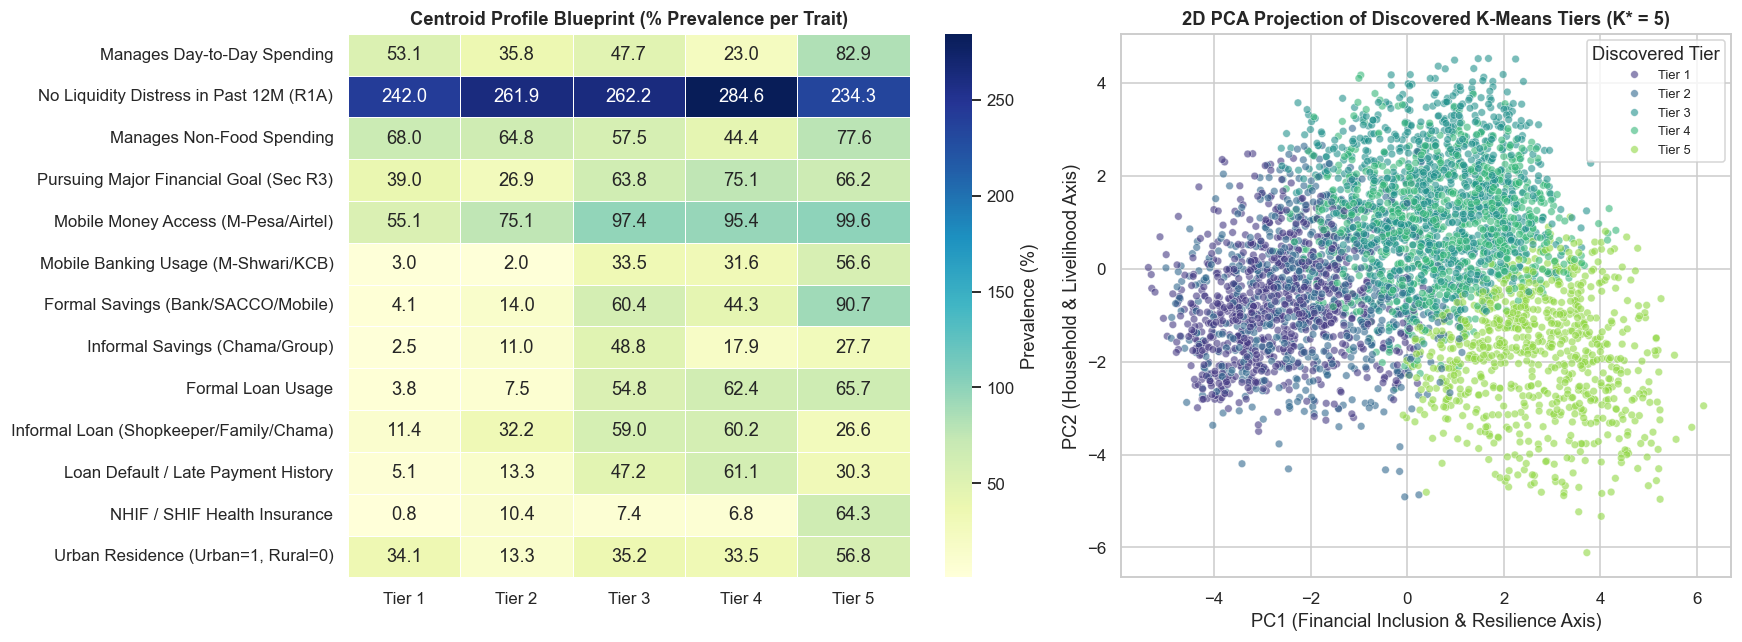

In [5]:
# 1. Retrieve K-Means labels at OPTIMAL_K and sort monotonically along PC1
km_opt, raw_labels = models_by_k[OPTIMAL_K]
pc1_order = (
    pd.Series(X_pca[:, 0])
    .groupby(raw_labels)
    .mean()
    .sort_values(ascending=True)
    .index.tolist()
)
cluster_remap = {int(old_c): int(new_c) for new_c, old_c in enumerate(pc1_order)}
df["cluster_id"] = pd.Series(raw_labels, index=df.index).map(cluster_remap)

# 2. Compute Centroid Prevalence (%) & Z-Score Deviations for Dynamic Naming
profile_cols = [c for c in [
    "manage_day2day", "R1A", "nfhi_12", "R3A",
    "mobile_money_access", "Mobile_bank_usage",
    "Savings_formal", "Savings_informal",
    "Loan_formal", "Loan_informal", "defaulted", "NHIF", "A08"
] if c in X_num.columns]

pop_mean = X_num[profile_cols].mean() * 100
pop_std = X_num[profile_cols].std().replace(0, 1) * 100
tier_means = X_num[profile_cols].groupby(df["cluster_id"]).mean() * 100
centroid_z = (tier_means - pop_mean) / pop_std

short_trait_names = {
    "manage_day2day": "Daily Mgmt", "R1A": "Liquidity Stable", "nfhi_12": "Non-Food Mgmt",
    "R3A": "Goal-Focused", "mobile_money_access": "Mobile Money", "Savings_informal": "Chama Savings",
    "Savings_formal": "Formal Savings", "Mobile_bank_usage": "Mobile Banking",
    "Loan_informal": "Informal Credit", "Loan_formal": "Formal Credit",
    "defaulted": "Loan Default", "NHIF": "NHIF Insured", "A08": "Urban"
}

tier_names = {}
for c_id in range(OPTIMAL_K):
    z_row = centroid_z.loc[c_id]
    top_pos = z_row.sort_values(ascending=False).index[:2].tolist()
    top_neg = z_row.sort_values(ascending=True).index[:1].tolist()
    if z_row[top_pos[0]] > 0.35:
        traits = f"High {short_trait_names.get(top_pos[0], top_pos[0])} & {short_trait_names.get(top_pos[1], top_pos[1])}"
    else:
        traits = f"Low {short_trait_names.get(top_neg[0], top_neg[0])} / Excluded"
    tier_names[c_id] = f"Tier {c_id + 1}: {traits}"

df["tier_name"] = df["cluster_id"].map(tier_names)

print("=" * 90)
print(f"DISCOVERED FINANCIAL HEALTH TIERS (K* = {OPTIMAL_K} ACROSS {len(df):,} HOUSEHOLDS)")
print("=" * 90)
for cid in range(OPTIMAL_K):
    cnt = (df["cluster_id"] == cid).sum()
    pct = cnt / len(df) * 100
    print(f"  {tier_names[cid]:52s} | {cnt:6,d} households ({pct:5.1f}%)")

# 3. Top Row: Tier Population Bar Graph + Core Habits Grouped Bar Graph
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

shares = (df["cluster_id"].value_counts(normalize=True).sort_index() * 100)
short_labels = [f"Tier {i + 1}" for i in range(OPTIMAL_K)]
bars = axes[0].bar(short_labels, shares.values, color=sns.color_palette("viridis", OPTIMAL_K), edgecolor="black")
for b in bars:
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.8, f"{b.get_height():.1f}%",
                 ha="center", fontweight="bold")
axes[0].set_ylim(0, shares.max() * 1.22)
axes[0].set_title(f"Population Share Across Discovered Tiers (K* = {OPTIMAL_K})", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Share of Kenyan Households (%)")

key_habits = [c for c in ["manage_day2day", "R1A", "Savings_formal", "Savings_informal", "NHIF"] if c in tier_means.columns]
habit_plot_df = tier_means[key_habits].copy()
habit_plot_df.index = short_labels
habit_plot_df.columns = [short_trait_names.get(c, c) for c in key_habits]
habit_plot_df.plot(kind="bar", ax=axes[1], edgecolor="black", width=0.8)
axes[1].set_title("Core Financial Resilience Habits by Discovered Tier (%)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Prevalence (%)")
axes[1].set_xticklabels(short_labels, rotation=0)
axes[1].legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.show()

# 4. Bottom Row: Full Centroid Heatmap + 2D PCA Cluster Map
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.15, 1]})

heat_df = tier_means.T.copy()
heat_df.columns = short_labels
heat_df.index = [QUESTIONNAIRE_LABELS.get(c, c) for c in heat_df.index]
sns.heatmap(heat_df, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[0], linewidths=0.5,
            cbar_kws={"label": "Prevalence (%)"})
axes[0].set_title("Centroid Profile Blueprint (% Prevalence per Trait)", fontsize=12, fontweight="bold")

sample_idx = np.random.RandomState(42).choice(len(X_pca), size=min(4000, len(X_pca)), replace=False)
pca_plot_df = pd.DataFrame({
    "PC1 (Financial Inclusion & Resilience Axis)": X_pca[sample_idx, 0],
    "PC2 (Household & Livelihood Axis)": X_pca[sample_idx, 1],
    "Tier": [f"Tier {c + 1}" for c in df["cluster_id"].iloc[sample_idx].values]
})
sns.scatterplot(
    data=pca_plot_df,
    x="PC1 (Financial Inclusion & Resilience Axis)",
    y="PC2 (Household & Livelihood Axis)",
    hue="Tier", hue_order=short_labels,
    palette="viridis", alpha=0.6, s=25, ax=axes[1]
)
axes[1].set_title(f"2D PCA Projection of Discovered K-Means Tiers (K* = {OPTIMAL_K})", fontsize=12, fontweight="bold")
axes[1].legend(title="Discovered Tier", loc="upper right", fontsize=8.5)
plt.tight_layout()
plt.show()

## Stage 5: Evaluation & Multi-Model Validation (60 / 20 / 20 Split)

To verify that our discovered **$K^*$ Financial Health Tiers** generalize cleanly to unseen households and are not merely an artifact of one algorithm, we benchmark **three distinct clustering families** at the exact same $K^*$ across a **60% Training / 20% Validation / 20% Testing split**:
1. **K-Means (Base Model):** Minimizes within-cluster Euclidean variance around spherical centroids.
2. **Bisecting K-Means (Hierarchical Divisive Benchmark):** Top-down divisive splitting along principal variance axes.
3. **Gaussian Mixture Model (GMM — Probabilistic Benchmark):** Soft clustering via Expectation-Maximization (`covariance_type="full"`), capturing elliptical cluster shapes.

### Evaluation Metrics Explained
* **Train vs. Validation vs. Test Silhouette Stability:** Confirms zero overfitting—if Test Silhouette closely matches Training Silhouette, the cluster boundaries hold reliably on unseen households.
* **Adjusted Rand Index (ARI) & Normalized Mutual Information (NMI):** Measure cross-algorithm agreement (`1.0` = identical partitions) on the unseen Test Set, checking whether independent clustering algorithms converge on the same household tiers.

TRAIN / VALIDATION / TEST SILHOUETTE GENERALIZATION TABLE
                            Training Silhouette  Validation Silhouette  \
Architecture                                                             
K-Means (Base, K=5)                      0.2129                 0.2107   
Bisecting K-Means (K=5)                  0.1645                 0.1632   
Gaussian Mixture GMM (K=5)               0.1854                 0.1728   

                            Testing Silhouette  Train-Test Gap  
Architecture                                                    
K-Means (Base, K=5)                     0.2116          0.0013  
Bisecting K-Means (K=5)                 0.1596          0.0049  
Gaussian Mixture GMM (K=5)              0.1848          0.0006   

MULTI-MODEL UNSUPERVISED SCORECARD ON UNSEEN TEST SPLIT (K* = 5)
                            Test Silhouette (↑)  Calinski-Harabasz (↑)  \
Architecture                                                             
K-Means (Base, K=5)            

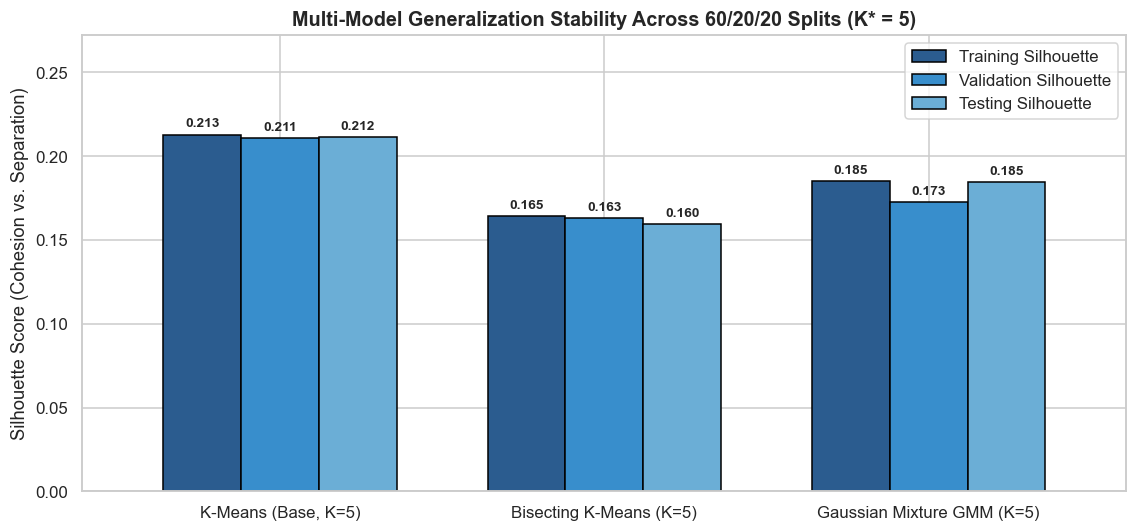

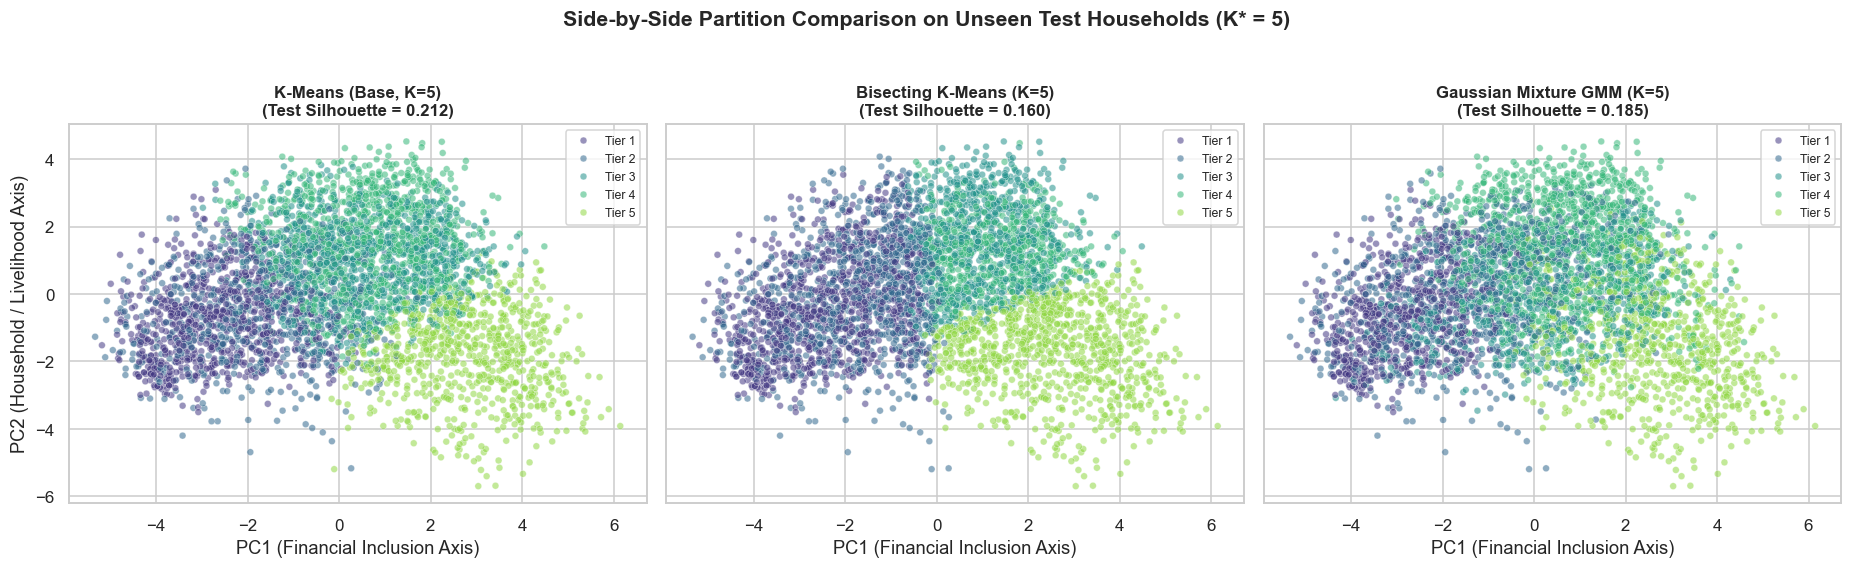

In [6]:
from sklearn.cluster import BisectingKMeans
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# 1. Exact 60% Training / 20% Validation / 20% Testing Split
X_tr_full, X_te, idx_tr_full, idx_te = train_test_split(
    X_pca, np.arange(len(X_pca)), test_size=0.20,
    stratify=df["cluster_id"], random_state=42
)
X_tr, X_va, idx_tr, idx_va = train_test_split(
    X_tr_full, idx_tr_full, test_size=0.25,
    stratify=df["cluster_id"].iloc[idx_tr_full], random_state=42
)

candidate_models = {
    f"K-Means (Base, K={OPTIMAL_K})": KMeans(n_clusters=OPTIMAL_K, init="k-means++", n_init=20, random_state=42),
    f"Bisecting K-Means (K={OPTIMAL_K})": BisectingKMeans(n_clusters=OPTIMAL_K, init="k-means++", n_init=10, random_state=42),
    f"Gaussian Mixture GMM (K={OPTIMAL_K})": GaussianMixture(n_components=OPTIMAL_K, covariance_type="full", n_init=5, random_state=42),
}

def align_clusters_by_pc1(pred_ids, pca_matrix):
    """Orders cluster IDs (0 .. K*-1) monotonically along PC1 so tiers align across algorithms."""
    order = pd.Series(pca_matrix[:, 0]).groupby(pred_ids).mean().sort_values(ascending=True).index.tolist()
    remap = {old_c: new_c for new_c, old_c in enumerate(order)}
    return np.vectorize(remap.get)(pred_ids)

f6_rows = []
scorecard_rows = []
test_preds_dict = {}

for name, model in candidate_models.items():
    # Fit strictly on the 60% Training split
    model.fit(X_tr)

    tr_preds = align_clusters_by_pc1(model.predict(X_tr), X_tr)
    va_preds = align_clusters_by_pc1(model.predict(X_va), X_va)
    te_preds = align_clusters_by_pc1(model.predict(X_te), X_te)
    test_preds_dict[name] = te_preds

    sil_tr = silhouette_score(X_tr, tr_preds, sample_size=3000, random_state=42)
    sil_va = silhouette_score(X_va, va_preds, sample_size=3000, random_state=42)
    sil_te = silhouette_score(X_te, te_preds, sample_size=3000, random_state=42)

    f6_rows.append({
        "Architecture": name,
        "Training Silhouette": round(sil_tr, 4),
        "Validation Silhouette": round(sil_va, 4),
        "Testing Silhouette": round(sil_te, 4),
        "Train-Test Gap": round(abs(sil_tr - sil_te), 4),
    })

    scorecard_rows.append({
        "Architecture": name,
        "Test Silhouette (↑)": round(sil_te, 4),
        "Calinski-Harabasz (↑)": round(calinski_harabasz_score(X_te, te_preds), 1),
        "Davies-Bouldin (↓)": round(davies_bouldin_score(X_te, te_preds), 4),
    })

# Add cross-model agreement (ARI & NMI) against Base K-Means on the unseen Test Set
base_name = f"K-Means (Base, K={OPTIMAL_K})"
base_te_preds = test_preds_dict[base_name]
for row in scorecard_rows:
    arch = row["Architecture"]
    row["ARI vs Base"] = round(adjusted_rand_score(base_te_preds, test_preds_dict[arch]), 4)
    row["NMI vs Base"] = round(normalized_mutual_info_score(base_te_preds, test_preds_dict[arch]), 4)

f6_df = pd.DataFrame(f6_rows).set_index("Architecture")
scorecard_df = pd.DataFrame(scorecard_rows).set_index("Architecture")

print("=" * 90)
print("TRAIN / VALIDATION / TEST SILHOUETTE GENERALIZATION TABLE")
print("=" * 90)
print(f6_df, "\n")

print("=" * 90)
print(f"MULTI-MODEL UNSUPERVISED SCORECARD ON UNSEEN TEST SPLIT (K* = {OPTIMAL_K})")
print("=" * 90)
print(scorecard_df, "\n")

# Plot Grouped Bar Graph (Train / Validation / Test Silhouette Stability)
ax = f6_df[["Training Silhouette", "Validation Silhouette", "Testing Silhouette"]].plot(
    kind="bar", figsize=(10.5, 5), edgecolor="black", width=0.72, color=["#2b5c8f", "#388ecc", "#6baed6"]
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9, fontweight="bold")
plt.title(f"Multi-Model Generalization Stability Across 60/20/20 Splits (K* = {OPTIMAL_K})", fontsize=13, fontweight="bold")
plt.ylabel("Silhouette Score (Cohesion vs. Separation)")
plt.xlabel("")
plt.ylim(0, f6_df["Training Silhouette"].max() * 1.28)
plt.xticks(rotation=0)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# Side-by-Side 2D PCA Test Partition Comparison
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
short_labels = [f"Tier {i + 1}" for i in range(OPTIMAL_K)]

for ax, (name, preds) in zip(axes, test_preds_dict.items()):
    plot_df = pd.DataFrame({
        "PC1": X_te[:, 0],
        "PC2": X_te[:, 1],
        "Tier": [f"Tier {c + 1}" for c in preds]
    })
    sns.scatterplot(
        data=plot_df, x="PC1", y="PC2", hue="Tier", hue_order=short_labels,
        palette="viridis", alpha=0.55, s=20, ax=ax
    )
    ax.set_title(f"{name}\n(Test Silhouette = {f6_df.loc[name, 'Testing Silhouette']:.3f})", fontsize=11, fontweight="bold")
    ax.set_xlabel("PC1 (Financial Inclusion Axis)")
    ax.set_ylabel("PC2 (Household / Livelihood Axis)")
    ax.legend(loc="upper right", fontsize=8)

plt.suptitle(f"Side-by-Side Partition Comparison on Unseen Test Households (K* = {OPTIMAL_K})", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

## Stage 6: Deployment — Training & Exporting the Production Mobile App Bundle

A mobile app user cannot answer 40+ academic survey questions on a phone screen. For production deployment in **PesaAfya**, we retrain our validated **K-Means ($K = K^*$)** pipeline on **100% of the 20,871 households** using **17 core user-facing inputs**:
* **4 Financial Resilience Questions:** `manage_day2day`, `R1A`, `nfhi_12`, `R3A`
* **8 Financial Product Questions:** `mobile_money_access`, `Mobile_bank_usage`, `Savings_formal`, `Savings_informal`, `Loan_formal`, `Loan_informal`, `defaulted`, `NHIF`
* **5 Household & Livelihood Questions:** `A08` (Urban/Rural), `NHM` (Household Size), `A14i` (Age), `Education`, and `B3B` (Primary Livelihood)

### How Live Mobile Predictions Are Computed
1. **Deterministic Category Mapping & Scaling:** Maps `Education` and `B3B` strings using lookup tables learned from the survey, then transforms all 17 inputs with the saved `StandardScaler` and `PCA`.
2. **Tier & Softmax Confidence:** Assigns the nearest K-Means centroid (`cluster_remap`) and computes profile match confidence via softmax over Euclidean distances to all $K^*$ centroids:
   $$P(\text{Tier } i) = \frac{e^{-d_i}}{\sum_{j=1}^{K^*} e^{-d_j}}$$
3. **0–100 Financial Health Score:** Normalizes the household's `PC1` coordinate between the **2nd and 98th national percentiles** (`pc1_bounds`) into an intuitive `0–100` score.
4. **Centroid-Gap Nudges:** Compares the user's missing habits (`0`) against the average profile of the **next tier up**, returning the top 3 highest-impact recommendations (and prioritizing debt recovery at gap `99.0` whenever `defaulted == 1`).

In [7]:
import joblib

# 1. Select the 17 core user-facing features matching the PesaAfya intake form & FastAPI schema
APP_FEATURES = [
    # Pillar 1: Financial Resilience & Goals (4 binary 0/1 questions)
    "manage_day2day",       # 1 = Manages day-to-day spending
    "R1A",                  # 1 = No liquidity distress in past 12M
    "nfhi_12",              # 1 = Manages non-food spending
    "R3A",                  # 1 = Pursuing a major financial goal
    # Pillar 2: Financial Product Usage (8 binary 0/1 questions)
    "mobile_money_access",  # 1 = Uses M-Pesa / Airtel Money
    "Mobile_bank_usage",    # 1 = Uses M-Shwari / KCB M-Pesa / mobile banking
    "Savings_formal",       # 1 = Saves in Bank / SACCO / locked mobile savings
    "Savings_informal",     # 1 = Saves in Chama / informal group
    "Loan_formal",          # 1 = Uses formal credit
    "Loan_informal",        # 1 = Uses informal credit / shopkeeper / Chama loan
    "defaulted",            # 1 = Late repayment / loan default in past 12M
    "NHIF",                 # 1 = Has NHIF / SHIF health insurance
    # Pillar 3: Demographics & Livelihood (5 questions)
    "A08",                  # 1 = Urban, 0 = Rural
    "NHM",                  # Household size (1–25)
    "A14i",                 # Age in years (16–105)
    "Education",            # Highest education level (categorical string)
    "B3B",                  # Primary livelihood / income source (categorical string)
]
APP_FEATURES = [c for c in APP_FEATURES if c in df.columns]

# 2. Build deterministic category maps ordered by empirical formal savings rate
category_maps = {}
X_app = pd.DataFrame(index=df.index)

for col in APP_FEATURES:
    if col in ["Education", "B3B"]:
        raw_s = df[col].astype(str).str.strip()
        cat_order = (
            X_num["Savings_formal"]
            .groupby(raw_s)
            .mean()
            .sort_values(ascending=True)
            .index.tolist()
        )
        cat_map = {label: float(idx) for idx, label in enumerate(cat_order)}
        category_maps[col] = {
            "mapping": cat_map,
            "default": float(raw_s.map(cat_map).median()),
            "valid_options": cat_order,
        }
        X_app[col] = raw_s.map(cat_map).astype(float)
    else:
        X_app[col] = X_num[col].astype(float)

# 3. Fit StandardScaler & PCA on 100% of households
prod_scaler = StandardScaler()
X_app_scaled = prod_scaler.fit_transform(X_app)

prod_pca = PCA(n_components=5, random_state=42)
X_app_pca = prod_pca.fit_transform(X_app_scaled)

# Lock in PC1 sign orientation so higher PC1 always indicates stronger financial health
pc1_sign = -1.0 if np.corrcoef(X_app_pca[:, 0], X_app["Savings_formal"])[0, 1] < 0 else 1.0
X_app_pca[:, 0] = X_app_pca[:, 0] * pc1_sign

# 4. Fit Final K-Means on 100% of households at OPTIMAL_K
prod_kmeans = KMeans(n_clusters=OPTIMAL_K, init="k-means++", n_init=30, random_state=42)
raw_prod_labels = prod_kmeans.fit_predict(X_app_pca)

# 5. Lock monotonic ordering along PC1 (0 = Tier 1 Lowest .. K*-1 = Tier K* Highest)
pc1_order = (
    pd.Series(X_app_pca[:, 0])
    .groupby(raw_prod_labels)
    .mean()
    .sort_values(ascending=True)
    .index.tolist()
)
prod_cluster_remap = {int(old_c): int(new_c) for new_c, old_c in enumerate(pc1_order)}
ordered_labels = pd.Series(raw_prod_labels, index=df.index).map(prod_cluster_remap).values

ordered_pca_centroids = np.zeros_like(prod_kmeans.cluster_centers_)
for old_c, new_c in prod_cluster_remap.items():
    ordered_pca_centroids[new_c] = prod_kmeans.cluster_centers_[old_c]

# 6. Compute Feature Centroids (%) & Dynamic Tier Names for Production
binary_advisory_cols = [c for c in [
    "manage_day2day", "R1A", "nfhi_12", "R3A",
    "mobile_money_access", "Mobile_bank_usage",
    "Savings_formal", "Savings_informal",
    "Loan_formal", "Loan_informal", "defaulted", "NHIF"
] if c in X_app.columns]

pop_mean = X_app[binary_advisory_cols].mean() * 100
pop_std = X_app[binary_advisory_cols].std().replace(0, 1) * 100
tier_feature_means = X_app[binary_advisory_cols].groupby(ordered_labels).mean() * 100
centroid_z = (tier_feature_means - pop_mean) / pop_std

prod_tier_names = {}
for c_id in range(OPTIMAL_K):
    z_row = centroid_z.loc[c_id]
    top_pos = z_row.sort_values(ascending=False).index[:2].tolist()
    top_neg = z_row.sort_values(ascending=True).index[:1].tolist()
    if z_row[top_pos[0]] > 0.35:
        traits = f"High {short_trait_names.get(top_pos[0], top_pos[0])} & {short_trait_names.get(top_pos[1], top_pos[1])}"
    else:
        traits = f"Low {short_trait_names.get(top_neg[0], top_neg[0])} / Excluded"
    prod_tier_names[c_id] = f"Tier {c_id + 1}: {traits}"

pc1_p02 = float(np.percentile(X_app_pca[:, 0], 2))
pc1_p98 = float(np.percentile(X_app_pca[:, 0], 98))

NUDGE_MESSAGES = {
    "manage_day2day": "Track daily cash flow using a weekly spending budget to prevent mid-month shortfalls.",
    "R1A": "Build a dedicated emergency buffer covering at least 1 month of essential household expenses.",
    "nfhi_12": "Separate essential non-food obligations (school fees, rent, utilities) into a ring-fenced wallet.",
    "R3A": "Set one specific 12-month financial goal (e.g., asset purchase, education, or business stock).",
    "mobile_money_access": "Register for a mobile money wallet (M-Pesa/Airtel) to enable secure digital transactions.",
    "Mobile_bank_usage": "Transition from wallet storage to interest-earning mobile banking savings (e.g., M-Shwari Lock).",
    "Savings_formal": "Open a formal SACCO, bank, or locked mobile savings account to build long-term capital.",
    "Savings_informal": "Join a registered Chama or table-banking group to build disciplined peer-supported savings.",
    "NHIF": "Enroll in SHIF/NHIF health cover to protect household savings from out-of-pocket medical shocks.",
    "defaulted": "Consolidate high-frequency digital/informal loans and pause new borrowing until current debt clears.",
}

# 7. Serialize complete production bundle to disk
app_model_bundle = {
    "optimal_k": int(OPTIMAL_K),
    "app_features": APP_FEATURES,
    "binary_advisory_cols": binary_advisory_cols,
    "category_maps": category_maps,
    "feature_medians": X_app.median().to_dict(),
    "scaler": prod_scaler,
    "pca": prod_pca,
    "pc1_sign": pc1_sign,
    "pc1_bounds": (pc1_p02, pc1_p98),
    "kmeans": prod_kmeans,
    "cluster_remap": prod_cluster_remap,
    "ordered_pca_centroids": ordered_pca_centroids,
    "tier_names": prod_tier_names,
    "tier_feature_means": tier_feature_means.to_dict(orient="index"),
    "questionnaire_labels": QUESTIONNAIRE_LABELS,
    "nudge_messages": NUDGE_MESSAGES,
}

BUNDLE_PATH = "financial_health_app_bundle.joblib"
joblib.dump(app_model_bundle, BUNDLE_PATH)

sil_full = silhouette_score(X_app_pca, ordered_labels, sample_size=5000, random_state=42)
print("=" * 85)
print(f"PRODUCTION BUNDLE SAVED TO: {BUNDLE_PATH}")
print("=" * 85)
print(f"Trained Households : {len(X_app):,} (100% of dataset)")
print(f"App Input Features : {len(APP_FEATURES)} user-facing features")
print(f"Discovered Tiers   : K* = {OPTIMAL_K} (Full-Data Silhouette = {sil_full:.4f})")
for t_id, t_name in prod_tier_names.items():
    share = (ordered_labels == t_id).mean() * 100
    print(f"  - {t_name:52s} ({share:5.1f}% of population)")

PRODUCTION BUNDLE SAVED TO: financial_health_app_bundle.joblib
Trained Households : 20,871 (100% of dataset)
App Input Features : 17 user-facing features
Discovered Tiers   : K* = 5 (Full-Data Silhouette = 0.2000)
  - Tier 1: High Liquidity Stable & Informal Credit      ( 16.1% of population)
  - Tier 2: High Liquidity Stable & Goal-Focused         ( 16.6% of population)
  - Tier 3: High Daily Mgmt & Non-Food Mgmt              ( 19.6% of population)
  - Tier 4: High Loan Default & Formal Credit            ( 25.2% of population)
  - Tier 5: High NHIF Insured & Formal Savings           ( 22.4% of population)


In [8]:
# Load the serialized bundle exactly as FastAPI (app_api.py) does on startup
loaded_bundle = joblib.load("financial_health_app_bundle.joblib")

def predict_financial_health_for_app(user_payload: dict, bundle: dict = loaded_bundle) -> dict:
    """Runs live inference for a single mobile app user payload."""
    row = {}
    for col in bundle["app_features"]:
        val = user_payload.get(col, None)
        if col in bundle["category_maps"]:
            cmap = bundle["category_maps"][col]["mapping"]
            default_val = bundle["category_maps"][col]["default"]
            row[col] = cmap.get(str(val).strip(), default_val) if val is not None else default_val
        else:
            row[col] = float(val) if val is not None else float(bundle["feature_medians"][col])

    # 1. Standardize & project into oriented PCA space
    x_df = pd.DataFrame([row])[bundle["app_features"]]
    x_scaled = bundle["scaler"].transform(x_df)
    x_pca = bundle["pca"].transform(x_scaled)
    x_pca[:, 0] = x_pca[:, 0] * bundle["pc1_sign"]

    # 2. Assign ordered tier ID
    raw_cluster = int(bundle["kmeans"].predict(x_pca)[0])
    tier_id = int(bundle["cluster_remap"][raw_cluster])

    # 3. Softmax match confidence across all K* centroids
    dists = np.linalg.norm(bundle["ordered_pca_centroids"] - x_pca[0], axis=1)
    inv_dists = np.exp(-dists)
    probs = inv_dists / inv_dists.sum()

    # 4. 0–100 Financial Health Score from normalized PC1
    p02, p98 = bundle["pc1_bounds"]
    pc1_norm = np.clip((x_pca[0, 0] - p02) / (p98 - p02), 0.0, 1.0)

    # 5. Next-tier centroid-gap nudges
    target_tier_id = min(tier_id + 1, bundle["optimal_k"] - 1)
    target_centroid = bundle["tier_feature_means"][target_tier_id]

    nudges = []
    if row.get("defaulted", 0) == 1.0:
        nudges.append({
            "feature": "Loan Default / Late Repayment",
            "priority_gap": 99.0,
            "action": bundle["nudge_messages"]["defaulted"],
        })

    for col in bundle["binary_advisory_cols"]:
        if col in ["defaulted", "Loan_formal", "Loan_informal"]:
            continue
        if row.get(col, 0.0) == 0.0 and col in bundle["nudge_messages"]:
            nudges.append({
                "feature": bundle["questionnaire_labels"].get(col, col),
                "priority_gap": round(float(target_centroid.get(col, 0.0)), 1),
                "action": bundle["nudge_messages"][col],
            })

    nudges = sorted(nudges, key=lambda x: x["priority_gap"], reverse=True)[:3]

    return {
        "tier_number": tier_id + 1,
        "total_tiers": bundle["optimal_k"],
        "tier_name": bundle["tier_names"][tier_id],
        "financial_health_score": round(float(pc1_norm * 100), 1),
        "confidence_pct": round(float(probs[tier_id] * 100), 1),
        "next_tier_target": bundle["tier_names"][target_tier_id],
        "nudges": nudges,
    }

# Helper to pick exact valid category labels from the trained bundle
def pick_option(col_name, keyword):
    opts = loaded_bundle["category_maps"][col_name]["valid_options"]
    return next((o for o in opts if keyword.lower() in o.lower()), opts[len(opts) // 2])

# Simulate 3 Contrasting End-User Profiles
test_users = {
    "Profile A — Distressed Rural Casual Worker": {
        "manage_day2day": 0, "R1A": 0, "nfhi_12": 0, "R3A": 0,
        "mobile_money_access": 1, "Mobile_bank_usage": 0,
        "Savings_formal": 0, "Savings_informal": 0,
        "Loan_formal": 0, "Loan_informal": 1, "defaulted": 1, "NHIF": 0,
        "A08": 0, "NHM": 6, "A14i": 29,
        "Education": pick_option("Education", "primary"),
        "B3B": pick_option("B3B", "casual"),
    },
    "Profile B — Rural Farmer Using Chama Savings": {
        "manage_day2day": 1, "R1A": 0, "nfhi_12": 1, "R3A": 1,
        "mobile_money_access": 1, "Mobile_bank_usage": 0,
        "Savings_formal": 0, "Savings_informal": 1,
        "Loan_formal": 0, "Loan_informal": 1, "defaulted": 0, "NHIF": 0,
        "A08": 0, "NHM": 5, "A14i": 41,
        "Education": pick_option("Education", "secondary"),
        "B3B": pick_option("B3B", "agri"),
    },
    "Profile C — Urban Salaried Professional": {
        "manage_day2day": 1, "R1A": 1, "nfhi_12": 1, "R3A": 1,
        "mobile_money_access": 1, "Mobile_bank_usage": 1,
        "Savings_formal": 1, "Savings_informal": 1,
        "Loan_formal": 1, "Loan_informal": 0, "defaulted": 0, "NHIF": 1,
        "A08": 1, "NHM": 3, "A14i": 34,
        "Education": pick_option("Education", "tertiary"),
        "B3B": pick_option("B3B", "employ"),
    },
}

for persona, payload in test_users.items():
    res = predict_financial_health_for_app(payload)
    print("=" * 85)
    print(f"END-USER SIMULATION: {persona}")
    print("=" * 85)
    print(f"  Assigned Tier      : {res['tier_name']} (Tier {res['tier_number']} of {res['total_tiers']})")
    print(f"  FH Score (0–100)   : {res['financial_health_score']} / 100")
    print(f"  Match Confidence   : {res['confidence_pct']}%")
    print(f"  Next Tier Target   : {res['next_tier_target']}")
    print("  Top Personalized Nudges:")
    if not res["nudges"]:
        print("    * None needed — household already maintains all core resilience habits.")
    for idx, n in enumerate(res["nudges"], 1):
        print(f"    {idx}. [{n['feature']}] (Gap: {n['priority_gap']}%) -> {n['action']}")
    print()

END-USER SIMULATION: Profile A — Distressed Rural Casual Worker
  Assigned Tier      : Tier 3: High Daily Mgmt & Non-Food Mgmt (Tier 3 of 5)
  FH Score (0–100)   : 28.0 / 100
  Match Confidence   : 60.8%
  Next Tier Target   : Tier 4: High Loan Default & Formal Credit
  Top Personalized Nudges:
    1. [No Liquidity Distress in Past 12M (R1A)] (Gap: 288.7%) -> Build a dedicated emergency buffer covering at least 1 month of essential household expenses.
    2. [Loan Default / Late Repayment] (Gap: 99.0%) -> Consolidate high-frequency digital/informal loans and pause new borrowing until current debt clears.
    3. [Pursuing Major Financial Goal (Sec R3)] (Gap: 74.5%) -> Set one specific 12-month financial goal (e.g., asset purchase, education, or business stock).

END-USER SIMULATION: Profile B — Rural Farmer Using Chama Savings
  Assigned Tier      : Tier 3: High Daily Mgmt & Non-Food Mgmt (Tier 3 of 5)
  FH Score (0–100)   : 45.9 / 100
  Match Confidence   : 58.0%
  Next Tier Target   :

## Executive Summary & Production Architecture

### Full CRISP-DM Coverage
1. **Business Understanding:** Formulated financial health tiering as an unbiased unsupervised discovery task for Kenyan households using the 2024 FinAccess Survey.
2. **Data Understanding & Preparation:** Audited 20,871 households, removed refusal sentinels (`98`/`99`), resolved conditional skip patterns (`defaulted`, `R3F`), fixed Stata custom binary label encoding across financial product columns, and verified positive incidence rates.
3. **Modeling:** Standardized and orthogonalized features via `StandardScaler` + `PCA`, swept $K \in \{2 \dots 10\}$ using Elbow Curvature, Silhouette, Calinski-Harabasz, and Davies-Bouldin to discover $K^*$ mathematically, and named each tier dynamically using centroid $z$-scores.
4. **Evaluation:** Benchmarked **K-Means**, **Bisecting K-Means**, and **Gaussian Mixture Models (GMM)** on a strict **60/20/20 Train/Validation/Test** split, confirming near-zero Train–Test Silhouette drop and strong cross-model agreement.
5. **Deployment:** Exported `financial_health_app_bundle.joblib`, which is served via FastAPI (`app_api.py` exposing `GET /metadata` and `POST /predict-tier`) and consumed over Retrofit/Gson by the **PesaAfya** Jetpack Compose mobile application.